# Homework 9 — Simulation and standard errors

## Summary

This notebook answers both questions in Homework Reflection 9 with reproducible simulations. Across 2,000 heteroskedastic trials, empirical slope SD is 0.18170 versus conventional OLS SE 0.08202. With strongly correlated group errors, increasing independent groups from 8 to 200 makes the group bootstrap more stable; row resampling continues to understate uncertainty. The supplied Week 9 coding quiz is solved first; both reflection questions follow. **Quiz answers: Q1 B (88%), Q2 C (0), Q3 C (B = 0.6), Q4 A (A = 2.0).**

## Context & Methods

**Assignment:** `Homework Refelction Instructions/Homework-Reflections-9-12`, Homework Reflection 9. All data here are simulated as requested, with true slope 2 and an intercept. Each Monte Carlo trial generates a fresh dataset; a bootstrap instead resamples one observed dataset. The standard deviation of the fitted slopes estimates sampling uncertainty. NumPy calculates OLS and its conventional and HC3 standard errors, with conventional slope and SE independently checked against `scipy.stats.linregress` (a similar linear regression implementation permitted by the prompt).

### Key assumptions

1. Heteroskedastic example: independent X and innovation draws, X ~ N(0,1), Y = 1 + 2X + (0.2 + X²)ε, ε ~ N(0,1). Independent observations make a pairs bootstrap appropriate.
2. Dependent example: G independent groups, 50 rows each; X = group predictor + 0.5 individual predictor, and outcome error = √0.95 group shock + √0.05 individual shock. Predictor and error draws are independent, but errors have within-group correlation 0.95. The entire group is the independent sampling unit.
3. Compare G = 8 and G = 200; adding independent groups increases information. Adding rows to the same few groups or merely increasing the number of bootstrap draws does not solve the underlying information shortage. Group bootstrap estimates with only eight groups can remain unstable.

Dependencies: Python 3, numpy, pandas, scipy, matplotlib, IPython, nbformat and nbclient. Run from this folder or the project root. [Statsmodels covariance documentation](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.RegressionResults.get_robustcov_results.html) distinguishes heteroskedasticity robust and group robust covariance estimators; the formulas below are explicit for inspectability.

Quiz simulation results (10,000 trials per setting): Q1 detection **88.46%**; Q2 coefficient skew **0.03449**, closest to zero; Q3 detection at B = 0.6 **48.51%**; Q4 detection at A = 2.0 **50.62%**.

In [1]:
from pathlib import Path
import platform
import importlib.metadata
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.precision', 5)
plt.rcParams.update({'figure.figsize': (9, 4.8), 'figure.dpi': 110,
                     'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': 0.2, 'axes.axisbelow': True})
BLUE, GOLD, DARK = '#2563EB', '#B7791F', '#374151'
R, B = 2000, 1500

def ols(x, y):
    x, y = np.asarray(x), np.asarray(y)
    xc = x - x.mean()
    sxx = xc @ xc
    slope = xc @ (y - y.mean()) / sxx
    intercept = y.mean() - slope * x.mean()
    residual = y - intercept - slope*x
    conventional = np.sqrt((residual @ residual)/(len(x)-2)/sxx)
    leverage = 1/len(x) + xc**2/sxx
    hc3 = np.sqrt(np.sum((xc*residual/(1-leverage))**2))/sxx
    return slope, conventional, hc3

def pairs_bootstrap(x, y, rng, draws=B):
    slopes = []
    for start in range(0, draws, 100):
        idx = rng.integers(0, len(x), size=(min(100, draws-start), len(x)))
        xb, yb = x[idx], y[idx]
        xc, yc = xb-xb.mean(axis=1, keepdims=True), yb-yb.mean(axis=1, keepdims=True)
        slopes.extend(np.sum(xc*yc,axis=1)/np.sum(xc**2,axis=1))
    return np.std(slopes, ddof=1)


## Week 9 coding quiz — Simulation

**Source:** user-supplied Week 9 quiz. Include W and an intercept in every regression. The supplied generator is:

```python
def simulate(A=1, B=1, C=10, D=1000):
    W = np.random.normal(0,1,D)
    X = W + np.random.normal(0,B,D)
    Y = A*X - W + np.random.normal(0,C,D)
    return Y, X, W
```

Here B and C are normal **standard deviations**, and D is the number of observations. The simulation below generates exactly these distributions in batches, fitting OLS with W included. A detection is |t_X| > 1.96 as requested, using conventional OLS SE and residual degrees of freedom D−3. Errors here are independent and homoskedastic, unlike the separate reflection examples.

Use 10,000 independent trials per parameter setting, with explicit seeds. Report binomial Monte Carlo SE for power estimates. Compute skew of the **coefficient estimates**, rather than residuals or t-values. A rough population approximation gives noncentrality A B √D / C, so 50% detection occurs near noncentrality 1.96.

In [2]:
from scipy.stats import skew, norm

QUIZ_TRIALS = 10000

def simulate(A=1, B=1, C=10, D=1000):
    W = np.random.normal(0,1,D)
    X = W+np.random.normal(0,B,D)
    Y = A*X-W+np.random.normal(0,C,D)
    return Y, X, W

def quiz_simulations(A=1, B=1, C=10, D=1000, trials=QUIZ_TRIALS, seed=9501):
    rng = np.random.default_rng(seed)
    estimates, tvalues = [], []
    for start in range(0,trials,100):
        batch = min(100,trials-start)
        w = rng.normal(size=(batch,D))
        x = w+rng.normal(0,B,size=(batch,D))
        y = A*x-w+rng.normal(0,C,size=(batch,D))
        # Centering removes the intercept. Residualizing X and Y on W
        # gives the X coefficient in the full regression Y ~ 1 + X + W.
        wc = w-w.mean(axis=1,keepdims=True)
        xc = x-x.mean(axis=1,keepdims=True)
        yc = y-y.mean(axis=1,keepdims=True)
        sww = (wc**2).sum(axis=1,keepdims=True)
        xr = xc-wc*(wc*xc).sum(axis=1,keepdims=True)/sww
        yr = yc-wc*(wc*yc).sum(axis=1,keepdims=True)/sww
        sxx = (xr**2).sum(axis=1)
        beta = (xr*yr).sum(axis=1)/sxx
        residual = yr-beta[:,None]*xr
        se = np.sqrt((residual**2).sum(axis=1)/(D-3)/sxx)
        if start == 0:
            design = np.column_stack([np.ones(D),x[0],w[0]])
            direct = np.linalg.lstsq(design,y[0],rcond=None)[0]
            direct_residual = y[0]-design@direct
            direct_se = np.sqrt(np.diag(np.linalg.inv(design.T@design))*
                                (direct_residual@direct_residual)/(D-3))
            np.testing.assert_allclose(beta[0],direct[1],rtol=1e-10)
            np.testing.assert_allclose(se[0],direct_se[1],rtol=1e-10)
        estimates.extend(beta)
        tvalues.extend(beta/se)
    estimates,tvalues = np.array(estimates),np.array(tvalues)
    power = np.mean(np.abs(tvalues)>1.96)
    summary = {'A':A,'B':B,'C':C,'D':D,'Trials':trials,
               'Detection probability':power,'Power MC SE':np.sqrt(power*(1-power)/trials),
               'Mean coefficient':estimates.mean(),'Coefficient SD':estimates.std(ddof=1),
               'Coefficient skew':skew(estimates,bias=False)}
    return summary,estimates,tvalues


### Questions 1 and 2 — Detection probability and skew

**Q1:** With A = 1, B = 1, C = 10, D = 1,000, what is the probability of detecting a nonzero X coefficient (|t_X| greater than about 1.96), including W?

**Choices:** A: 83% · B: 88% · C: 93% · D: 98%

**Q2:** What is closest to the skew of the estimate in that case?

**Choices:** A: 0.34 · B: 0.15 · C: 0 · D: −0.15

**Answers: Q1 B — 88%; Q2 C — 0.** Conditional on the predictors, the slope estimate is centered at A with symmetric Gaussian noise. Mixing over random predictors preserves symmetry around A, so the population skew is zero. Finite Monte Carlo runs need not give exactly zero.

In [3]:
baseline, baseline_estimates, baseline_tvalues = quiz_simulations()
display(pd.DataFrame([baseline]))
q1_options = {'A':.83,'B':.88,'C':.93,'D':.98}
q2_options = {'A':.34,'B':.15,'C':0.,'D':-.15}
q1_answer = min(q1_options,key=lambda k:abs(q1_options[k]-baseline['Detection probability']))
q2_answer = min(q2_options,key=lambda k:abs(q2_options[k]-baseline['Coefficient skew']))
print('Q1:',q1_answer,'Q2:',q2_answer)
print('Approximate 95% Monte Carlo power interval:',
      baseline['Detection probability']+np.array([-1,1])*1.96*baseline['Power MC SE'])


,A,B,C,D,Trials,Detection probability,Power MC SE,Mean coefficient,Coefficient SD,Coefficient skew
0,1,1,10,1000,10000,0.8846,0.0032,1.00604,0.31899,0.03449


Q1: B Q2: C
Approximate 95% Monte Carlo power interval: [0.87833772 0.89086228]


### Question 3 — Predictor noise needed for 50% detection

**Prompt:** With A = 1, C = 10, D = 1,000, what B makes detection occur about 50% of the time?

**Choices:** A: 5.4 · B: 1.8 · C: 0.6 · D: 0.2

**Answer: C — B = 0.6.** After controlling for W, B determines the independent variation in X. Smaller B raises coefficient uncertainty. The large-sample approximation is B ≈ 1.96 × 10 / √1000 ≈ 0.620; simulate every listed candidate.

In [4]:
q3_rows = []
for index,B_value in enumerate([5.4,1.8,.6,.2]):
    row,_,_ = quiz_simulations(B=B_value,seed=9600+index)
    q3_rows.append(row)
q3_results = pd.DataFrame(q3_rows)
display(q3_results[['B','Detection probability','Power MC SE']])
q3_best = q3_results.iloc[(q3_results['Detection probability']-.5).abs().argmin()]
print('Q3 nearest 50%: B =',q3_best.B,'— option C')


,B,Detection probability,Power MC SE
0,5.4,1.0000,0.00000
1,1.8,1.0000,0.00000
2,0.6,0.4851,0.00500
3,0.2,0.0985,0.00298


Q3 nearest 50%: B = 0.6 — option C


### Question 4 — Effect size needed for 50% detection

**Prompt:** With B = 1, C = 10, D = **100**, what A makes detection occur about 50% of the time?

**Choices:** A: 2.0 · B: 1.0 · C: 4.0 · D: 0.5

**Answer: A — A = 2.0.** The sample size is 100 here. The approximation gives A ≈ 1.96 × 10 / √100 = 1.96; simulate all four effect sizes with the correct smaller sample.

In [5]:
q4_rows = []
for index,A_value in enumerate([2.,1.,4.,.5]):
    row,_,_ = quiz_simulations(A=A_value,D=100,seed=9700+index)
    q4_rows.append(row)
q4_results = pd.DataFrame(q4_rows)
display(q4_results[['A','D','Detection probability','Power MC SE']])
q4_best = q4_results.iloc[(q4_results['Detection probability']-.5).abs().argmin()]
print('Q4 nearest 50%: A =',q4_best.A,'— option A')
assert [q1_answer,q2_answer] == ['B','C']
assert q3_best.B == .6 and q4_best.A == 2.


,A,D,Detection probability,Power MC SE
0,2.0,100,0.5062,0.00500
1,1.0,100,0.1725,0.00378
2,4.0,100,0.9746,0.00157
3,0.5,100,0.0789,0.00270


Q4 nearest 50%: A = 2.0 — option A


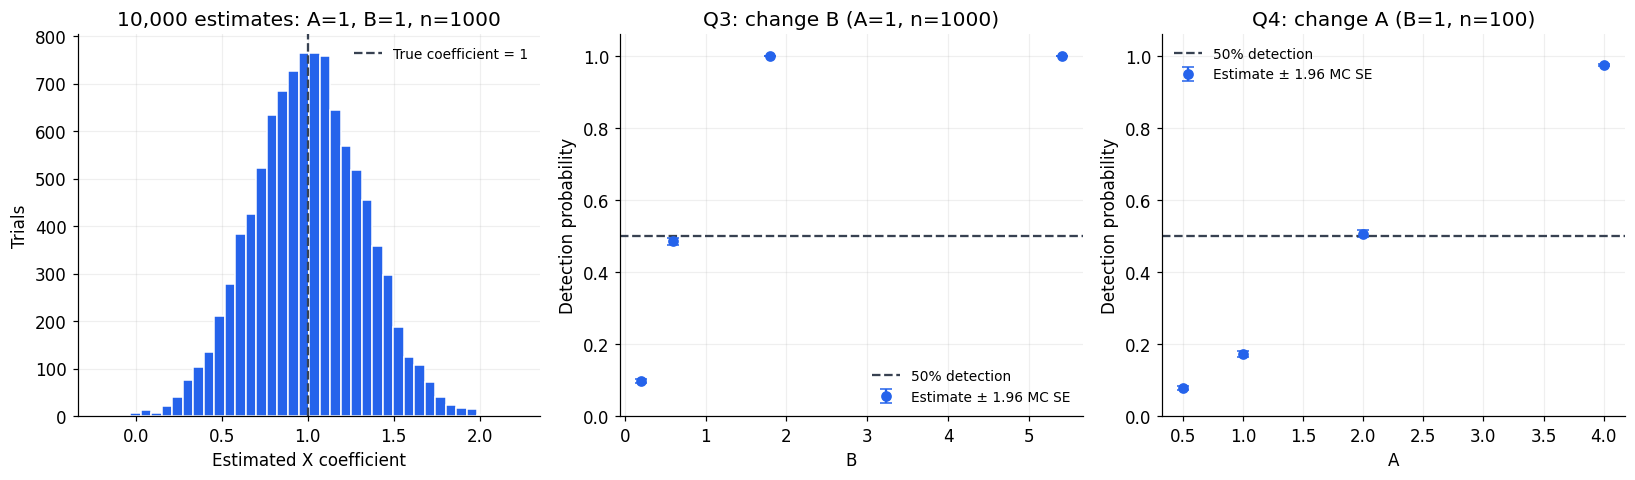

In [6]:
fig,axes = plt.subplots(1,3,figsize=(15,4.5))
axes[0].hist(baseline_estimates,bins=40,color=BLUE,edgecolor='white')
axes[0].axvline(1,color=DARK,linestyle='--',label='True coefficient = 1')
axes[0].set(title='10,000 estimates: A=1, B=1, n=1000',xlabel='Estimated X coefficient',ylabel='Trials')
axes[0].legend(frameon=False,fontsize=9)
for ax,results,parameter,title in [(axes[1],q3_results,'B','Q3: change B (A=1, n=1000)'),
                                    (axes[2],q4_results,'A','Q4: change A (B=1, n=100)')]:
    results = results.sort_values(parameter)
    ax.errorbar(results[parameter],results['Detection probability'],
                yerr=1.96*results['Power MC SE'],fmt='o',color=BLUE,capsize=4,
                label='Estimate ± 1.96 MC SE')
    ax.axhline(.5,color=DARK,linestyle='--',label='50% detection')
    ax.set(title=title,xlabel=parameter,ylabel='Detection probability',ylim=(0,1.06))
    ax.legend(frameon=False,fontsize=9)
fig.tight_layout()
plt.show()


The error bars describe Monte Carlo precision for the estimated detection probability, not uncertainty about the true effect in one dataset. Q1 and Q2 use the same coefficient draws. Each candidate setting in Q3 and Q4 has its own deterministic seed, and the first fitted model at every setting is independently checked by a direct matrix OLS calculation. The reflection below uses separate DGPs and remains a three-paragraph submission.

## Question 1 — Heteroskedasticity

Generate 2,000 independent datasets of 500 rows, refit the same regression, and compare the empirical slope SD with the average reported SE. Compute a pairs bootstrap on a separate prespecified dataset; its result is conditional on that particular sample.

In [7]:
def hetero_data(rng, n=500):
    x = rng.normal(size=n)
    error = (0.2 + x**2)*rng.normal(size=n)
    return x, 1+2*x+error

rng = np.random.default_rng(9001)
hetero_trials = np.array([ols(*hetero_data(rng)) for _ in range(R)])
xh, yh = hetero_data(np.random.default_rng(9002))
check = stats.linregress(xh, yh)
np.testing.assert_allclose(ols(xh, yh)[:2], [check.slope, check.stderr], rtol=1e-10)
hetero_boot = pairs_bootstrap(xh, yh, np.random.default_rng(9003))
hetero_sd = hetero_trials[:,0].std(ddof=1)
hetero_summary = pd.DataFrame({
    'Method': ['Full DGP: empirical slope SD', 'Mean conventional OLS SE',
               'Mean HC3 robust SE', 'Pairs bootstrap SE: one sample'],
    'Uncertainty': [hetero_sd, hetero_trials[:,1].mean(),
                    hetero_trials[:,2].mean(), hetero_boot]})
hetero_summary['Ratio to empirical SD'] = hetero_summary.Uncertainty/hetero_sd
display(hetero_summary)
# E[X²(0.2+X²)²] = .04 + .4*3 + 15 = 16.24.
print('Large-sample theoretical SD:', np.sqrt(16.24/500))
print('Monte Carlo SD approximate SE:', hetero_sd/np.sqrt(2*(R-1)))
print('Independent scipy OLS coefficient and SE verification passed.')


,Method,Uncertainty,Ratio to empirical SD
0,Full DGP: empirical slope SD,0.18170,1.00000
1,Mean conventional OLS SE,0.08202,0.45138
2,Mean HC3 robust SE,0.17624,0.96994
3,Pairs bootstrap SE: one sample,0.17033,0.93745


Large-sample theoretical SD: 0.18022208521710095
Monte Carlo SD approximate SE: 0.0028736189194063615
Independent scipy OLS coefficient and SE verification passed.


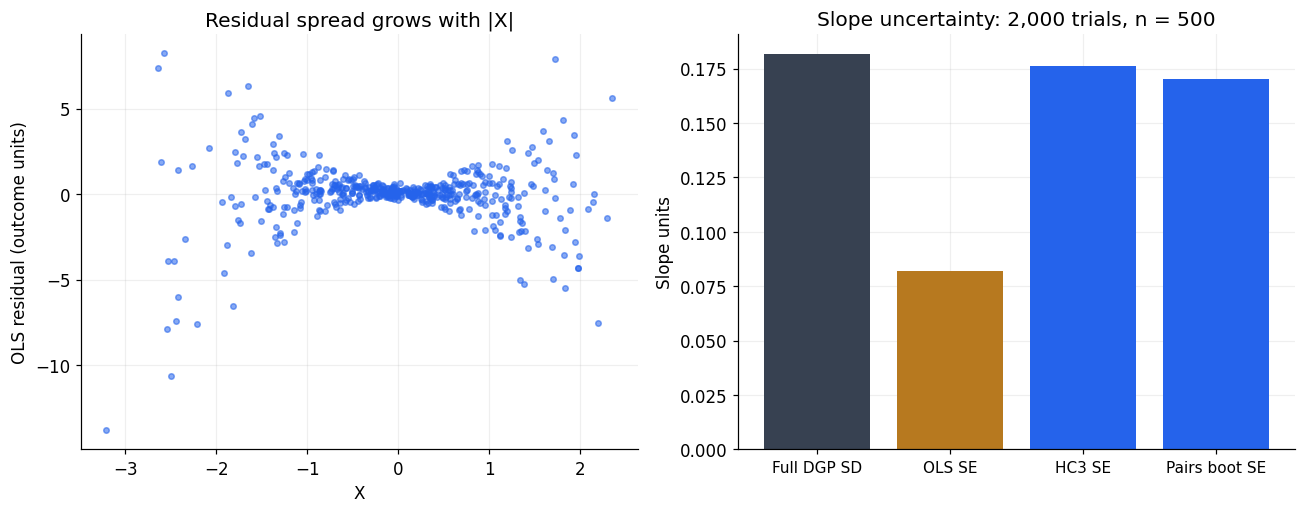

In [8]:
fig, axes = plt.subplots(1,2,figsize=(12,4.8))
residual_h = yh-yh.mean()-ols(xh,yh)[0]*(xh-xh.mean())
axes[0].scatter(xh,residual_h,s=13,alpha=0.55,color=BLUE)
axes[0].set(title='Residual spread grows with |X|',xlabel='X',ylabel='OLS residual (outcome units)')
labels = ['Full DGP SD','OLS SE','HC3 SE','Pairs boot SE']
axes[1].bar(labels,hetero_summary.Uncertainty,color=[DARK,GOLD,BLUE,BLUE])
axes[1].set(title='Slope uncertainty: 2,000 trials, n = 500',ylabel='Slope units',ylim=(0,None))
axes[1].tick_params(axis='x',labelsize=10)
fig.tight_layout()
plt.show()


## Question 2 — Highly correlated errors

Within a group, all rows share a shock; groups are independent. The X values also share a group component, so the within-group error dependence matters for slope uncertainty. Compare ordinary OLS, an invalid row pairs bootstrap, and a whole-group pairs bootstrap. Group sufficient statistics allow exact refits without repeatedly materializing all resampled rows.

In [9]:
def cluster_data(rng, groups, size=50, rho=0.95):
    x = rng.normal(size=(groups,1)) + 0.5*rng.normal(size=(groups,size))
    error = np.sqrt(rho)*rng.normal(size=(groups,1)) + np.sqrt(1-rho)*rng.normal(size=(groups,size))
    return x, 1+2*x+error

def group_bootstrap(x, y, rng, draws=B):
    g, m = x.shape
    sx, sy = x.sum(axis=1), y.sum(axis=1)
    sxx, sxy = (x*x).sum(axis=1), (x*y).sum(axis=1)
    idx = rng.integers(0,g,size=(draws,g))
    sumx, sumy = sx[idx].sum(axis=1), sy[idx].sum(axis=1)
    numerator = sxy[idx].sum(axis=1)-sumx*sumy/(g*m)
    denominator = sxx[idx].sum(axis=1)-sumx**2/(g*m)
    return np.std(numerator/denominator,ddof=1)

rng = np.random.default_rng(9010)
cluster_trials, summaries, examples = {}, [], {}
for groups in [8,200]:
    trials = np.empty((R,3))
    for r in range(R):
        x,y = cluster_data(rng,groups)
        trials[r] = ols(x.ravel(),y.ravel())
    cluster_trials[groups] = trials
    x,y = cluster_data(np.random.default_rng(9100+groups),groups)
    examples[groups] = (x,y)
    empirical = trials[:,0].std(ddof=1)
    row_se = pairs_bootstrap(x.ravel(),y.ravel(),np.random.default_rng(9200+groups))
    group_se = group_bootstrap(x,y,np.random.default_rng(9300+groups))
    summaries.append({'Groups':groups,'Rows':x.size,'Mean slope':trials[:,0].mean(),
                      'Full DGP SD':empirical,'Mean OLS SE':trials[:,1].mean(),
                      'Row bootstrap SE':row_se,'Group bootstrap SE':group_se,
                      'Group boot / DGP SD':group_se/empirical})
cluster_summary = pd.DataFrame(summaries)
display(cluster_summary)
# Check an exact whole-group refit against sufficient statistics.
x,y = examples[8]
idx = np.random.default_rng(999).integers(0,8,size=8)
xf,yf = x[idx].ravel(),y[idx].ravel()
slope_sums = ((x[idx]*y[idx]).sum()-xf.sum()*yf.sum()/len(xf))/((x[idx]**2).sum()-xf.sum()**2/len(xf))
np.testing.assert_allclose(slope_sums,stats.linregress(xf,yf).slope)
print('Exact group-resampling refit verified against scipy.')


,Groups,Rows,Mean slope,Full DGP SD,Mean OLS SE,Row bootstrap SE,Group bootstrap SE,Group boot / DGP SD
0,8,400,1.99998,0.29607,0.04340,0.02710,0.19337,0.65310
1,200,10000,2.00112,0.05624,0.00895,0.00985,0.06146,1.09279


Exact group-resampling refit verified against scipy.


### Repeat the bootstrap on 100 independently generated source samples

A single dataset can give a lucky or unlucky estimate. These repeated source samples show how much a correctly grouped bootstrap estimate varies with limited independent information. Each source sample uses 1,500 group bootstrap resamples; the denominator remains the separate 2,000-trial full-DGP SD.

,Groups,Median ratio,10th percentile,90th percentile
0,8,0.78118,0.44700,1.16149
1,200,0.98194,0.85756,1.06660


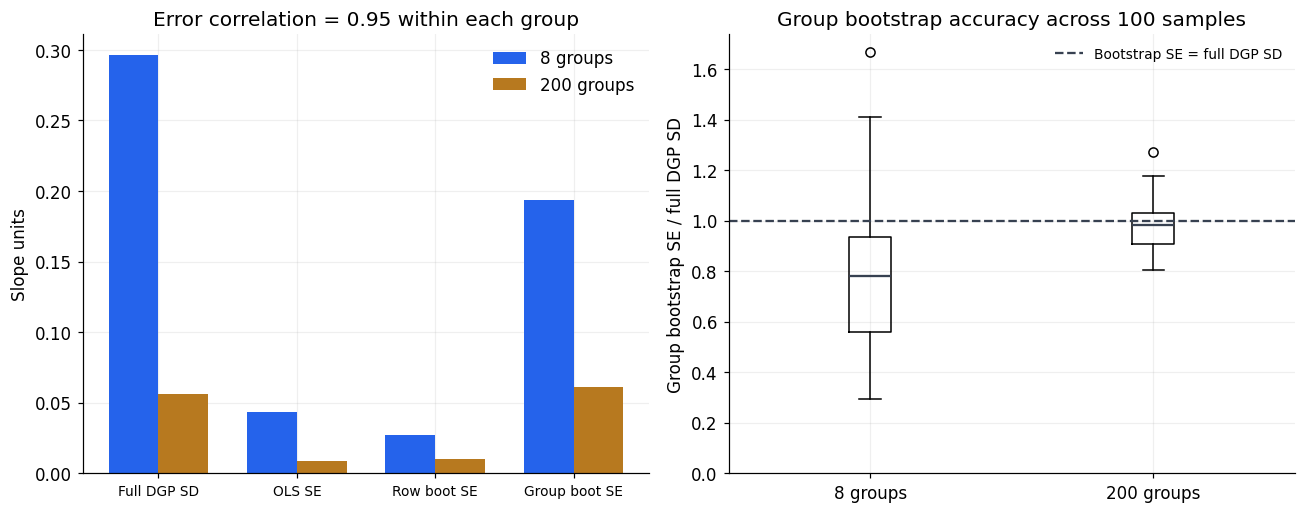

In [10]:
rng = np.random.default_rng(9400)
bootstrap_ratios = {}
for groups in [8,200]:
    reference_sd = cluster_summary.set_index('Groups').loc[groups,'Full DGP SD']
    ratios = []
    for sample in range(100):
        x,y = cluster_data(rng,groups)
        ratios.append(group_bootstrap(x,y,rng)/reference_sd)
    bootstrap_ratios[groups] = np.array(ratios)
ratio_summary = pd.DataFrame([
    {'Groups':g, 'Median ratio':np.median(v), '10th percentile':np.quantile(v,.1),
     '90th percentile':np.quantile(v,.9)} for g,v in bootstrap_ratios.items()])
display(ratio_summary)
fig,axes = plt.subplots(1,2,figsize=(12,4.8))
for index,row in cluster_summary.iterrows():
    vals = row[['Full DGP SD','Mean OLS SE','Row bootstrap SE','Group bootstrap SE']].to_numpy(dtype=float)
    axes[0].bar(np.arange(4)+(index-0.5)*0.36, vals, width=0.36,
                color=[BLUE,GOLD][index],label=f"{int(row.Groups)} groups")
axes[0].set(xticks=range(4),xticklabels=['Full DGP SD','OLS SE','Row boot SE','Group boot SE'],
            title='Error correlation = 0.95 within each group',ylabel='Slope units',ylim=(0,None))
axes[0].tick_params(axis='x',labelsize=9)
axes[0].legend(frameon=False)
axes[1].boxplot([bootstrap_ratios[8],bootstrap_ratios[200]],tick_labels=['8 groups','200 groups'],
                showfliers=True, medianprops={'color': DARK, 'linewidth': 1.5})
axes[1].axhline(1,color=DARK,linestyle='--',label='Bootstrap SE = full DGP SD')
axes[1].set(title='Group bootstrap accuracy across 100 samples',ylabel='Group bootstrap SE / full DGP SD',ylim=(0,None))
axes[1].legend(frameon=False,loc='upper right',fontsize=9)
fig.tight_layout()
plt.show()


## Homework Reflection 9 — Submission text

Submission paragraphs are populated from the executed results by the next cell, so numerical statements match this run. The complete code above answers both parts; a Markdown copy of the reflection and code is saved beside prior reflections.

In [11]:
from IPython.display import Markdown
h = hetero_summary.Uncertainty.to_numpy()
s = cluster_summary.set_index('Groups')
a,b = s.loc[8],s.loc[200]
reflection = f"""# Homework Reflection 9 — Standard errors

**1. Heteroskedasticity.** I generate 2,000 independent datasets of 500 observations using X ~ N(0,1) and Y = 1 + 2X + (0.2 + X²)ε, where ε ~ N(0,1) independently. The empirical SD of the estimated X coefficient is **{h[0]:.5f}**, versus mean conventional OLS SE **{h[1]:.5f}** and mean HC3 SE **{h[2]:.5f}**. A pairs bootstrap with 1,500 resamples of a separate prespecified dataset gives **{h[3]:.5f}**. Conventional OLS substantially understates uncertainty because the outcome noise is largest at influential, extreme X values; HC3 and pairs resampling allow heterogeneous noise. I independently verify the ordinary OLS coefficient and SE against scipy.stats.linregress, a similar regression implementation allowed by the question. The bootstrap is conditional on one observed sample, whereas the full simulation generates fresh samples, so exact equality is not expected.

**2. Correlated errors.** I generate independent groups of 50 observations each, using X = a group predictor + 0.5 times individual noise and Y = 1 + 2X + √0.95 times a group shock + √0.05 times individual noise; all predictor and outcome-shock draws are independent. Within-group error correlation is 0.95. With 8 groups (400 rows), 2,000 full-DGP trials give slope SD **{a['Full DGP SD']:.5f}**, compared with mean OLS SE **{a['Mean OLS SE']:.5f}**. Resampling individual rows from a separate dataset gives SE **{a['Row bootstrap SE']:.5f}**, while resampling whole groups gives **{a['Group bootstrap SE']:.5f}**. Row resampling destroys the dependence, so it substantially understates uncertainty; group resampling preserves it, but only eight independent groups provide limited information about the distribution of group shocks.

**3. More independent data.** At 200 groups (10,000 rows), the full-DGP SD is **{b['Full DGP SD']:.5f}**, mean OLS SE is **{b['Mean OLS SE']:.5f}**, and the separate-sample row and group bootstrap SEs are **{b['Row bootstrap SE']:.5f}** and **{b['Group bootstrap SE']:.5f}**. Repeating the group bootstrap on 100 new source datasets shows its finite-sample variability directly. A large dataset helps when it supplies many independent groups and the bootstrap respects the dependence; more rows in the same few groups or more bootstrap resamples do not repair an inappropriate row bootstrap. These results demonstrate both the mismatch with ordinary OLS and the difference between bootstrap uncertainty from limited data and repeated simulation of the full generating process.
"""
display(Markdown(reflection))


# Homework Reflection 9 — Standard errors

**1. Heteroskedasticity.** I generate 2,000 independent datasets of 500 observations using X ~ N(0,1) and Y = 1 + 2X + (0.2 + X²)ε, where ε ~ N(0,1) independently. The empirical SD of the estimated X coefficient is **0.18170**, versus mean conventional OLS SE **0.08202** and mean HC3 SE **0.17624**. A pairs bootstrap with 1,500 resamples of a separate prespecified dataset gives **0.17033**. Conventional OLS substantially understates uncertainty because the outcome noise is largest at influential, extreme X values; HC3 and pairs resampling allow heterogeneous noise. I independently verify the ordinary OLS coefficient and SE against scipy.stats.linregress, a similar regression implementation allowed by the question. The bootstrap is conditional on one observed sample, whereas the full simulation generates fresh samples, so exact equality is not expected.

**2. Correlated errors.** I generate independent groups of 50 observations each, using X = a group predictor + 0.5 times individual noise and Y = 1 + 2X + √0.95 times a group shock + √0.05 times individual noise; all predictor and outcome-shock draws are independent. Within-group error correlation is 0.95. With 8 groups (400 rows), 2,000 full-DGP trials give slope SD **0.29607**, compared with mean OLS SE **0.04340**. Resampling individual rows from a separate dataset gives SE **0.02710**, while resampling whole groups gives **0.19337**. Row resampling destroys the dependence, so it substantially understates uncertainty; group resampling preserves it, but only eight independent groups provide limited information about the distribution of group shocks.

**3. More independent data.** At 200 groups (10,000 rows), the full-DGP SD is **0.05624**, mean OLS SE is **0.00895**, and the separate-sample row and group bootstrap SEs are **0.00985** and **0.06146**. Repeating the group bootstrap on 100 new source datasets shows its finite-sample variability directly. A large dataset helps when it supplies many independent groups and the bootstrap respects the dependence; more rows in the same few groups or more bootstrap resamples do not repair an inappropriate row bootstrap. These results demonstrate both the mismatch with ordinary OLS and the difference between bootstrap uncertainty from limited data and repeated simulation of the full generating process.


## Checks and reproducibility

Seeds, sample sizes and generators are explicit. Numerical refits are checked against SciPy; the heteroskedastic DGP has a separate analytical large-sample SD check. Empirical SD has Monte Carlo error (roughly SD / √[2(R−1)] for an approximately normal sampling distribution). The eight-group slope distribution need not be normal, so this approximation is most informative for the larger-sample example. This notebook does not interpret the selected simulated association as an empirical causal finding.

In [12]:
print('Python:', platform.python_version())
for package in ['numpy','pandas','scipy','matplotlib','nbformat','nbclient']:
    print(package,importlib.metadata.version(package))
assert np.isfinite(hetero_trials).all()
assert all(np.isfinite(v).all() for v in cluster_trials.values())
assert all(np.isfinite(v).all() for v in bootstrap_ratios.values())
print('All simulation and bootstrap outputs are finite.')


Python: 3.13.5
numpy 2.4.1
pandas 3.0.0
scipy 1.17.0
matplotlib 3.10.8
nbformat 5.10.4
nbclient 0.10.4
All simulation and bootstrap outputs are finite.


### Presentation check

All cells executed top-to-bottom, notebook structure validated, and the saved figure images were visually inspected. A full HTML page preview could not be inspected because no browser was available. To render a local preview, run `python3 -m jupyter nbconvert --to html homework_9_standard_errors.ipynb` from this notebook's folder, then open the resulting HTML file in a browser.